# Mạng Nơ-ron Đa tầng (Multi-Layer Perceptron - MLP)

Mạng Nơ-ron là một hệ thống tính toán lấy cảm hứng từ cấu trúc não bộ, bao gồm nhiều lớp các "tế bào" (Neurons) liên kết với nhau.

**1. Cấu trúc MLP:**
*   **Lớp đầu vào (Input Layer):** Tiếp nhận đặc trưng của dữ liệu (ví dụ: tọa độ x, y).
*   **Lớp ẩn (Hidden Layers):** Nơi diễn ra các biến đổi phi tuyến. Mỗi Nơ-ron trong lớp này tính tổng trọng số của tất cả các tín hiệu từ lớp trước, cộng với một độ lệch (bias), và đi qua hàm kích hoạt (ReLU, Tanh).
    $$a_j = \text{ReLU}\left(\sum_{i} w_{ij} x_i + b_j\right)$$
*   **Lớp đầu ra (Output Layer):** Chuyển đổi tín hiệu cuối cùng thành kết quả dự đoán.

**2. Huấn luyện bằng SGD (Stochastic Gradient Descent):**
Quá trình huấn luyện mạng trải qua một vòng lặp lặp đi lặp lại:
1.  **Forward Pass:** Đưa dữ liệu qua mạng để lấy dự đoán.
2.  **Tính Loss:** Đo lường sai số giữa dự đoán và nhãn thực tế (ví dụ: Mean Squared Error - MSE).
3.  **Zero Gradients:** Xóa sạch các đạo hàm (gradient) từ bước trước.
4.  **Backward Pass:** Gọi `loss.backward()` để tự động tính đạo hàm của hàm Loss theo từng trọng số $w$ và $b$ thông qua Autograd Engine.
5.  **Cập nhật tham số (Update):** Dịch chuyển trọng số đi ngược hướng gradient để giảm Loss.
    $$w = w - \text{learning\_rate} \times \frac{\partial Loss}{\partial w}$$

In [1]:
import random
import numpy as np

# 1. Nâng cấp Value Class (Bổ sung phép trừ và lũy thừa để tính Loss)
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "Chỉ hỗ trợ lũy thừa với số thực/nguyên"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad += (other * (self.data ** (other - 1))) * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')
        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward
        return out

    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __radd__(self, other): return self + other
    def __rmul__(self, other): return self * other

    def backward(self):
        topo, visited = [], set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev: build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        for node in reversed(topo): node._backward()

# 2. Xây dựng Kiến trúc Mạng Nơ-ron
class Module:
    def zero_grad(self):
        for p in self.parameters(): p.grad = 0.0
    def parameters(self): return []

class Neuron(Module):
    def __init__(self, nin, nonlin=True):
        # Khởi tạo trọng số ngẫu nhiên từ -1 đến 1
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(0.0)
        self.nonlin = nonlin

    def __call__(self, x):
        # Tính Tích vô hướng (Dot product): w*x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return act.relu() if self.nonlin else act

    def parameters(self):
        return self.w + [self.b]

class Layer(Module):
    def __init__(self, nin, nout, **kwargs):
        self.neurons = [Neuron(nin, **kwargs) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP(Module):
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        # Các lớp ẩn dùng hàm phi tuyến ReLU, Lớp cuối cùng trả về giá trị tuyến tính
        self.layers = [Layer(sz[i], sz[i+1], nonlin=(i != len(nouts)-1)) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

Tổng số tham số của mô hình: 337
Epoch  10 | Loss: 0.3588
Epoch  20 | Loss: 0.3091
Epoch  30 | Loss: 0.2771
Epoch  40 | Loss: 0.2564
Epoch  50 | Loss: 0.2369
Epoch  60 | Loss: 0.2208
Epoch  70 | Loss: 0.2057
Epoch  80 | Loss: 0.1912
Epoch  90 | Loss: 0.1746
Epoch 100 | Loss: 0.1590


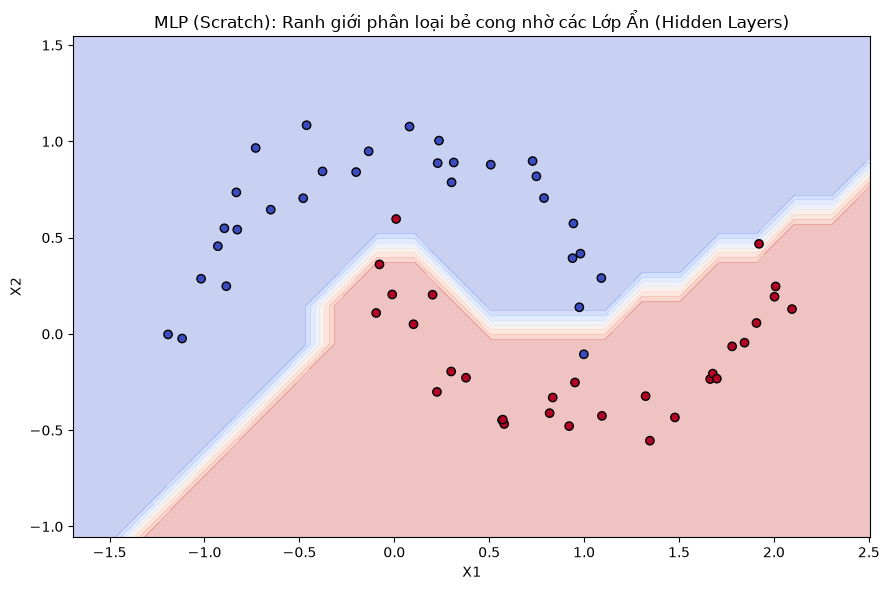

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# 1. Sinh dữ liệu phi tuyến (Hai hình bán nguyệt lồng nhau)
# Dùng bộ dữ liệu nhỏ (60 mẫu) vì Autograd Scratch chạy bằng Python thuần khá chậm
np.random.seed(42)
random.seed(42)
X, y = make_moons(n_samples=60, noise=0.1)
# Đổi nhãn từ {0, 1} thành {-1, 1} để phù hợp với loss function (Hinge/MSE style)
y = y * 2 - 1 

# 2. Khởi tạo Mạng Nơ-ron: 2 Input -> Lớp ẩn 16 -> Lớp ẩn 16 -> 1 Output
model = MLP(2, [16, 16, 1])
print(f"Tổng số tham số của mô hình: {len(model.parameters())}")

# 3. Vòng lặp Huấn luyện (Training Loop)
epochs = 100
learning_rate = 0.05

for k in range(epochs):
    # a. Forward pass
    ypred = [model(x) for x in X]
    
    # b. Tính hàm Loss (Mean Squared Error - MSE)
    # L = trung bình của tổng (y_pred - y_true)^2
    losses = [(yout - ygt)**2 for yout, ygt in zip(ypred, y)]
    total_loss = sum(losses) * (1.0 / len(losses))
    
    # c. Zero gradients
    model.zero_grad()
    
    # d. Backward pass (Phép màu của Autograd nằm ở đây)
    total_loss.backward()
    
    # e. Cập nhật tham số (SGD Update)
    for p in model.parameters():
        p.data -= learning_rate * p.grad
        
    if (k+1) % 10 == 0:
        print(f"Epoch {k+1:3d} | Loss: {total_loss.data:.4f}")

# 4. Trực quan hóa Decision Boundary
# Giảm độ phân giải meshgrid (0.2 thay vì 0.02) để biểu đồ render nhanh hơn
plt.figure(figsize=(9, 6))
h = 0.2
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

X_mesh = np.c_[xx.ravel(), yy.ravel()]
# Dự đoán trên toàn bộ lưới không gian
Z = np.array([model(x).data for x in X_mesh])
Z = np.where(Z > 0, 1, -1)
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title("MLP (Scratch): Ranh giới phân loại bẻ cong nhờ các Lớp Ẩn (Hidden Layers)")
plt.xlabel("X1")
plt.ylabel("X2")
plt.tight_layout()
plt.show()

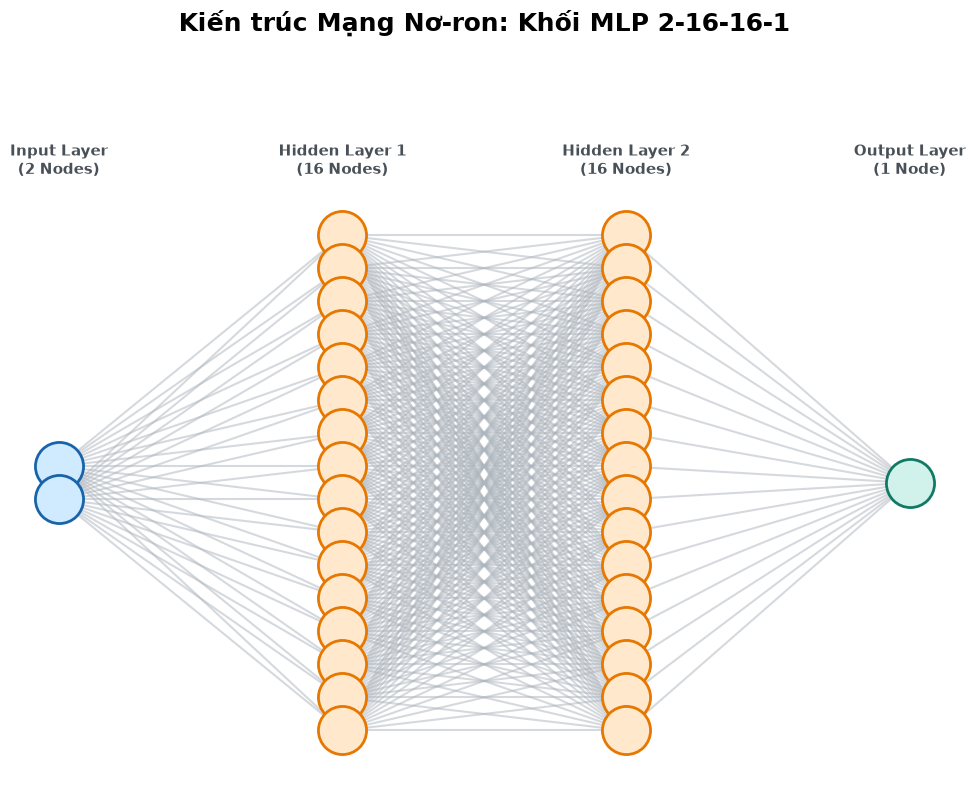

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def draw_neural_net_architecture_fixed(layer_sizes):
    # Set tỷ lệ khung hình thành 10:8 (thay vì 14:8) để cho các lớp sát nhau
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.axis('off')
    
    n_layers = len(layer_sizes)
    max_neurons = max(layer_sizes)
    
    # Thiết lập khoảng cách thu phóng tĩnh (x: chiều ngang, y: chiều dọc)
    x_spacing = 1.0 
    y_spacing = 1.0

    # 1. Tính toán tọa độ X, Y để dàn đều các Nơ-ron và căn giữa trục Y
    layer_coords = []
    for i, n_neurons in enumerate(layer_sizes):
        x = i * x_spacing
        y_start = (n_neurons - 1) * y_spacing / 2
        y_coords = [y_start - j * y_spacing for j in range(n_neurons)]
        layer_coords.append(list(zip([x]*n_neurons, y_coords)))

    # 2. Vẽ các đường liên kết Trọng số (Weights)
    # Đặt zorder=1 và alpha=0.5 để đường line chìm xuống dưới, tạo sự liền mạch
    # Tăng độ đậm (linewidth) và độ rõ (alpha) của các đường kết nối
    for i in range(n_layers - 1):
        for coord1 in layer_coords[i]:
            for coord2 in layer_coords[i+1]:
                ax.plot([coord1[0], coord2[0]], [coord1[1], coord2[1]], 
                        c='#adb5bd', alpha=0.5, linewidth=1.5, zorder=1)

    # 3. Vẽ các khối Nơ-ron (Neurons)
    # Phối màu hiện đại (Input: Xanh, Hidden: Cam, Output: Xanh lục)
    colors = ['#d0ebff', '#ffe8cc', '#ffe8cc', '#d1f2eb']
    edge_colors = ['#1864ab', '#e67700', '#e67700', '#117a65']
    labels = ['Input Layer\n(2 Nodes)', 'Hidden Layer 1\n(16 Nodes)', 
              'Hidden Layer 2\n(16 Nodes)', 'Output Layer\n(1 Node)']

    for i, coords in enumerate(layer_coords):
        xs, ys = zip(*coords)
        # Tăng kích thước node lên 1200
        ax.scatter(xs, ys, s=1200, c=colors[i], edgecolors=edge_colors[i], 
                   zorder=2, linewidths=2)

        # Tiêu đề cho từng Layer
        # Đẩy nhãn của layer lên cao hẳn so với node trên cùng
        ax.text(i * x_spacing, (max_neurons * y_spacing / 2) + 1.2, labels[i], 
                ha='center', va='bottom', fontsize=11, fontweight='bold', color='#495057')

    # BỔ SUNG: Nới rộng trục Y lên trên thêm 4 đơn vị để có không gian cho các Nhãn (Labels)
    ax.set_ylim(bottom=-(max_neurons * y_spacing / 2) - 1, top=(max_neurons * y_spacing / 2) + 4)

    # Dùng pad=40 để đẩy tiêu đề tách biệt hoàn toàn khỏi đồ thị
    plt.title("Kiến trúc Mạng Nơ-ron: Khối MLP 2-16-16-1", fontsize=18, pad=40, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Kích hoạt hàm trực quan hóa với kiến trúc của mô hình hiện tại
draw_neural_net_architecture_fixed([2, 16, 16, 1])